In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
from tqdm import tqdm

import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.util_machine_learning as uml
import utils.visualization as vis

import test_code.dfield_approach_elastix.constants as cts
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

from scipy import stats

from features_loader import FeaturesLoader

np.set_printoptions(precision=4)


SERVER: False


# Load data

703


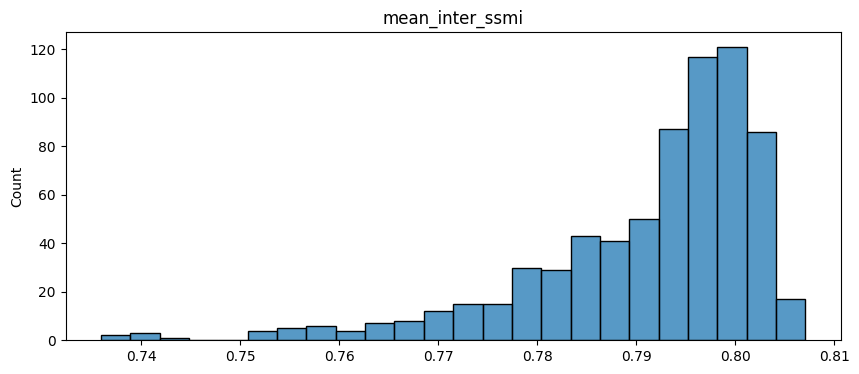

703


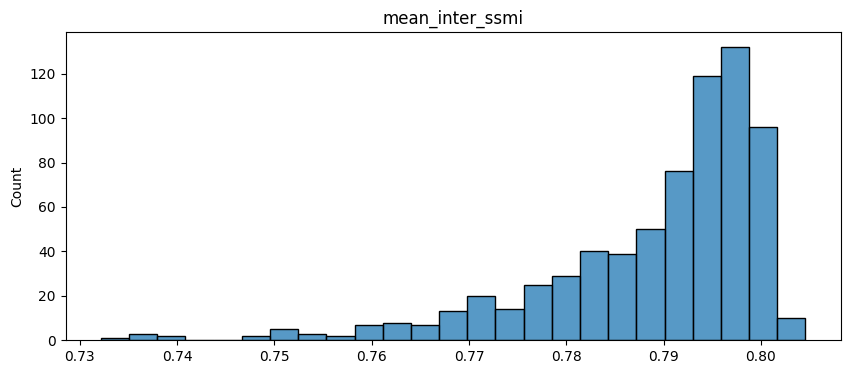

In [6]:
for hunt in [4,3]:
    reader = FeaturesLoader(pil.get_matching_ids(), hunt=hunt)
    data = reader.get_all_images_similarity_table("ssim")
    np.fill_diagonal(data.values, 1)
    column_means = data.mean(axis=1)


    # display(data.head())
    # display(column_means.head())
    # print(util.get_basic_metrics_str(column_means))
    vis.plot_hist(column_means, "mean_inter_ssmi", bins="auto", kde=False, binrange=None, figsize=(10, 4))

# data_sorted = data.sort_values(by='ssim')
# display(data_sorted.head())

# data_ids = data.pop('patient_id').tolist()
# data_columns = data.columns.tolist()

# vis.plot_data_voxplot(data, data_columns, figsize=(10,5))


# vis.plot_hist_all_data_df(data, bins="auto", binrange=None, figsize=(10, 4))

# # vis.plot_hits_df(data, "ssim", bins="auto", kde=False, binrange=None, figsize=(10, 4))
# # vis.plot_hits_df(data, "ssim", bins="auto", kde=False, binrange=None, figsize=(10, 4))
# # vis.plot_hits_df(data, "ncc", bins="auto", kde=False, binrange=None, figsize=(10, 4))


# Preprocessing

### Remove outlayers

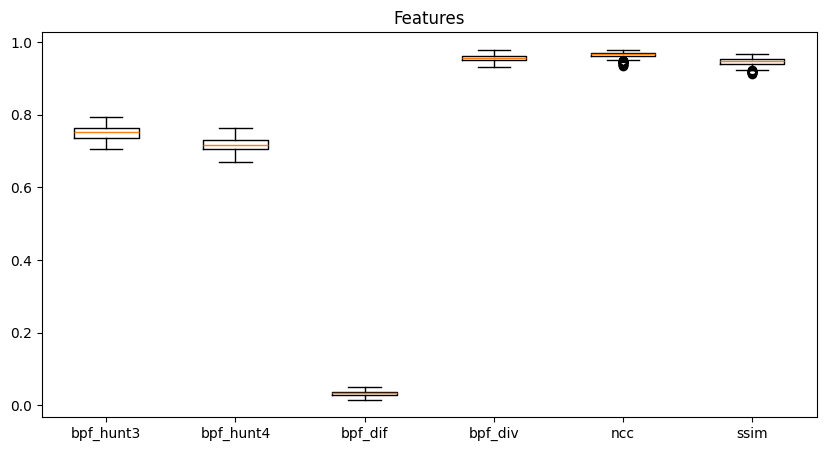

In [3]:
data_no_outlayers, no_outlayers_index, outlayers_index = uml.remove_outliers_zscore(data.values, threshold=2.5)
data_ids_no_outlayers = np.array(data_ids)[no_outlayers_index].tolist()
vis.plot_data_voxplot(data_no_outlayers, data_columns, figsize=(10,5))


### Standarize and normalize

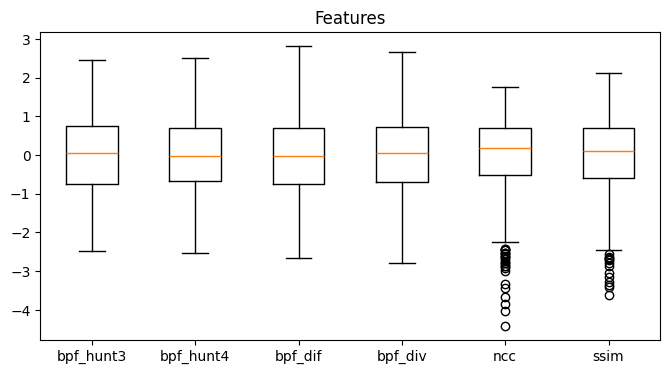

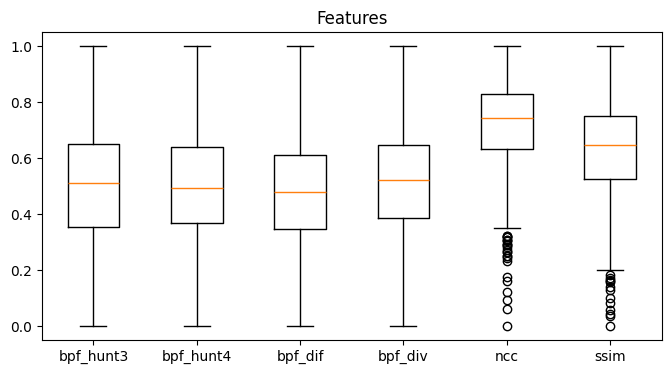

In [4]:
data_standardized, standarizer = uml.standarize_columns(data_no_outlayers)
data_normalized, normalizer = uml.normalize_columns(data_standardized)
data_normalized_df = pd.DataFrame(data_normalized, columns=data_columns)

vis.plot_data_voxplot(data_standardized, data_columns, figsize=(8,4))
vis.plot_data_voxplot(data_normalized, data_columns, figsize=(8,4))


### Correlation

High correlated: ['bpf_hunt3', 'bpf_dif']


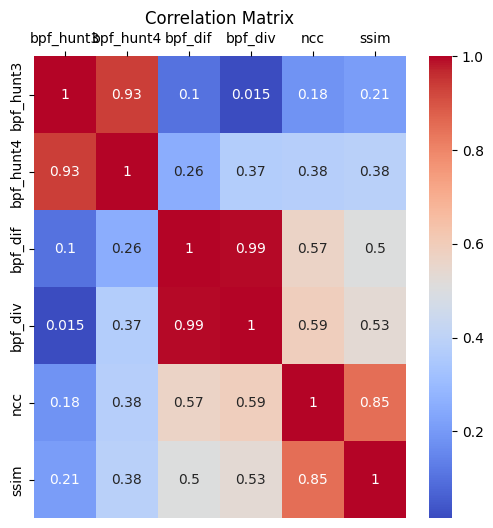

In [5]:
corr_df, to_drop = uml.correlation_df(data_normalized_df, corr_th=0.9)

print(f"High correlated: {to_drop}")
vis.plot_data_precomputed_correlation_df(corr_df, figsize=(6, 6))



### Visualize individual features

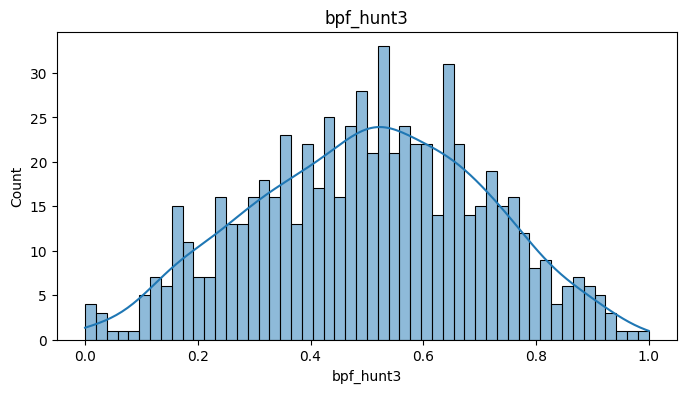

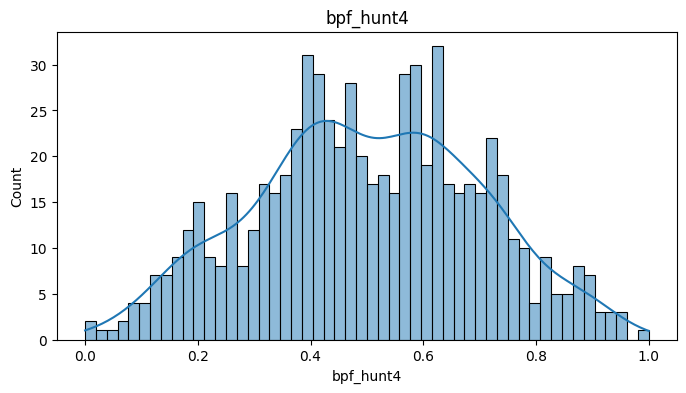

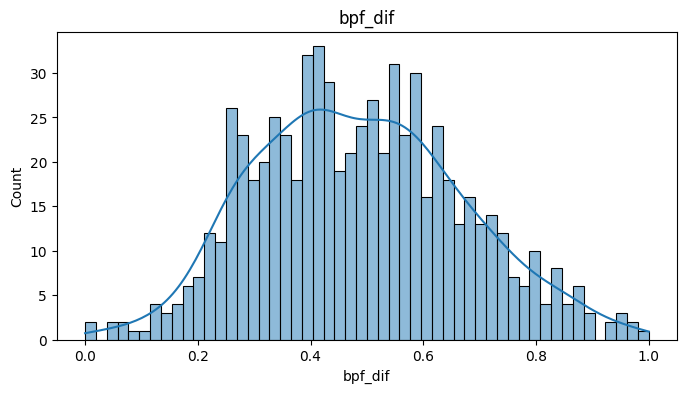

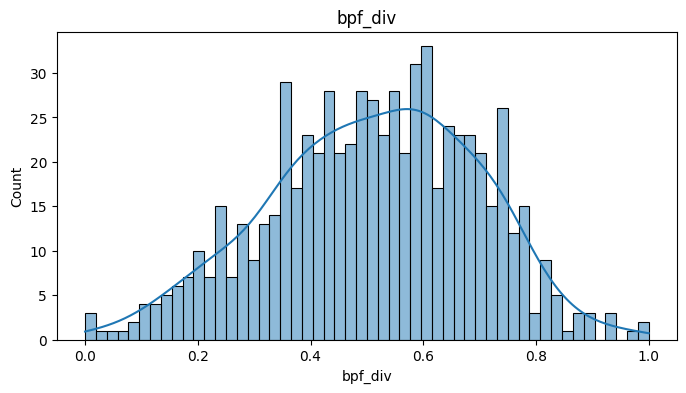

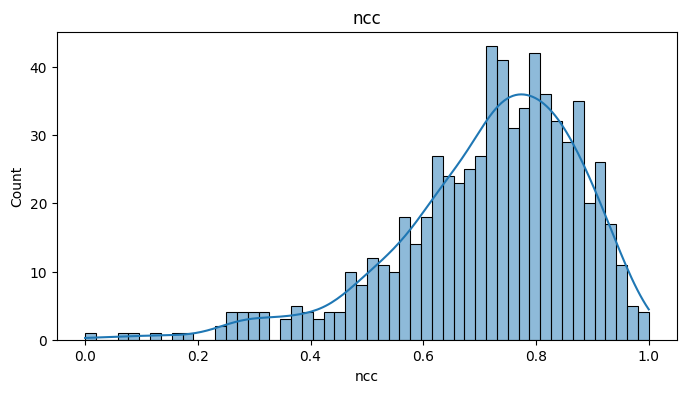

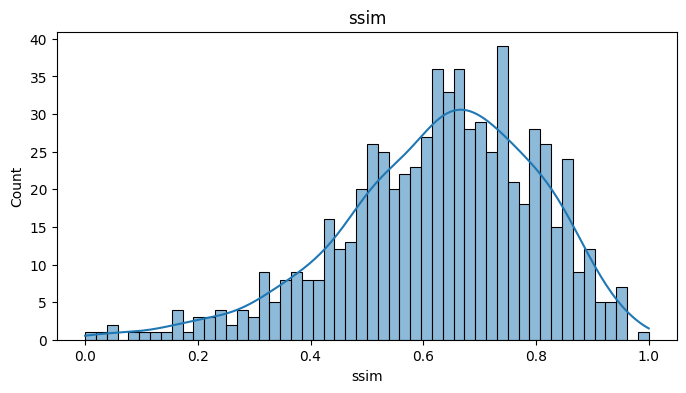

In [6]:
bins = int(np.sqrt(data_normalized.shape[0]))*2
# bins="auto"
binrange = (0.0,1.0)
data_to_hist_df = data_normalized_df

vis.plot_hist_all_data_df(data_to_hist_df, bins=bins, binrange=binrange, figsize=(8, 4))

### Visualize 2D

In [7]:
# vis.plot_2D_points_2v2_all_data_df(data_to_hist_df, figsize=(5, 5))

### PCA

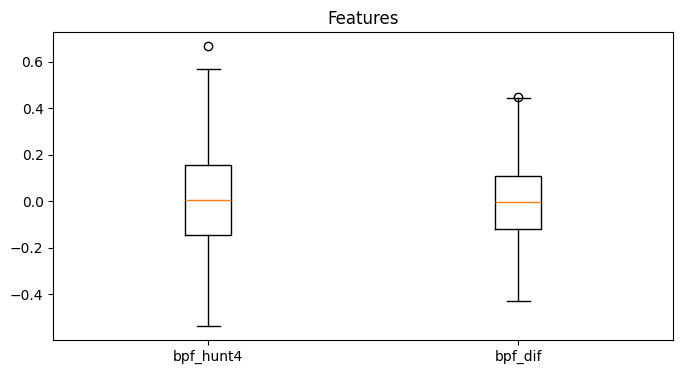

In [19]:
pca_columns = ["bpf_hunt4", "bpf_dif"]
pca_obj = PCA(n_components=len(pca_columns))
data_pca = pca_obj.fit_transform(data_normalized_df[pca_columns])
data_pca_df = pd.DataFrame(data_pca, columns=pca_columns)

vis.plot_data_voxplot(data_pca, pca_columns, figsize=(8,4))



# Clustering

### Bynary clustering

(array([0, 1, 2, 3]), array([154, 195, 203, 133], dtype=int64))


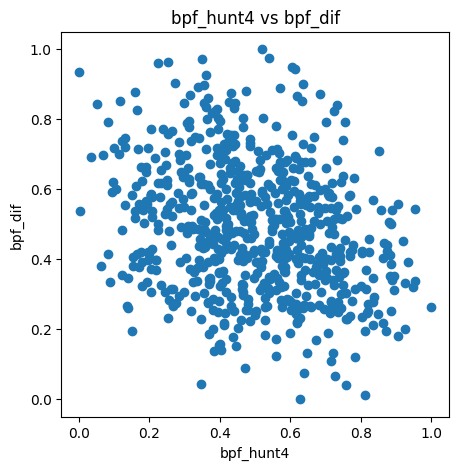

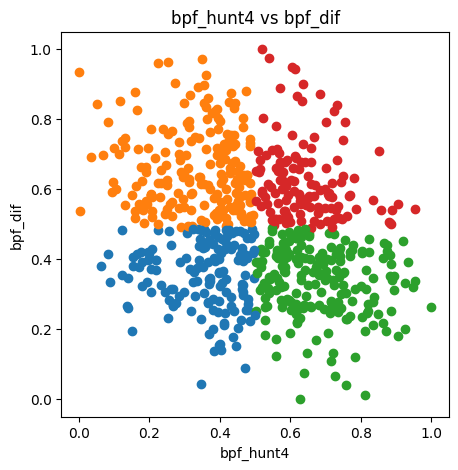

In [23]:
columns = ["bpf_hunt4", "bpf_dif"]
column_1 = "bpf_hunt4"
column_2 = "bpf_dif"


data_to_cluster = data_normalized_df  
clusters = uml.cluster_by_mean_df(data_to_cluster, columns)
# clusters = uml.cluster_by_mean_with_center_df(data_to_cluster, columns, 0.2)

print(np.unique(clusters, return_counts=True))
vis.plot_2D_points(data_to_cluster[column_1], data_to_cluster[column_2], column_1, column_2, clusters=None, figsize=(5, 5)) 
vis.plot_2D_points(data_to_cluster[column_1], data_to_cluster[column_2], column_1, column_2, clusters=clusters, figsize=(5, 5)) 



(array([0, 1, 2, 3]), array([174, 161, 173, 177], dtype=int64))


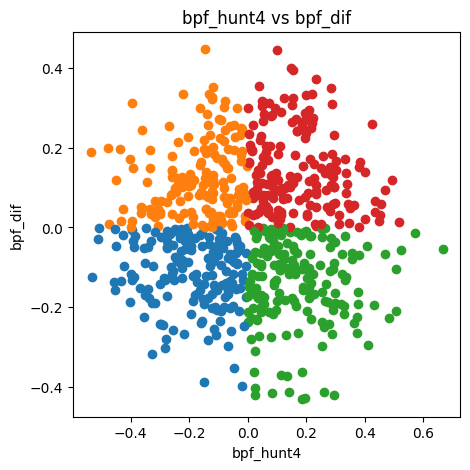

In [21]:

_data_to_cluster = data_pca_df
clusters = uml.cluster_by_mean_df(_data_to_cluster, columns)
# clusters = uml.cluster_by_mean_with_center_df(_data_to_cluster, columns, 0.2)

print(np.unique(clusters, return_counts=True))
vis.plot_2D_points(_data_to_cluster[column_1], _data_to_cluster[column_2], column_1, column_2, clusters=clusters, figsize=(5, 5)) 


In [12]:
nb_clusters = 16
random_state = 42

def count_not_matching_clusters(clusters1, clusters2):
    count = 0
    for i in range(len(clusters1)):
        if clusters1[i] != clusters2[i]:
            count += 1
    return count

## K-means

In [13]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=nb_clusters, random_state=random_state)
clusters_kmeans = kmeans.fit_predict(data_pca)
# print(clusters_kmeans)
print(np.unique(np.array(clusters_kmeans), return_counts=True)[1])

# [34 10 33 19 19 26 28 19 29  3  5 21 24  9  9 15]
# [38 19 46 40  1 11  7 20 16 24 27 11 35  3  1  4]

[66 43 39 50 45 29 35 57 48 34 23 32 18 43 58 65]


## EM

In [14]:
from sklearn.mixture import GaussianMixture

# Crear el objeto GaussianMixture
gmm = GaussianMixture(n_components=nb_clusters, random_state=random_state, init_params='kmeans', max_iter=10000, tol=1e-6)
clusters_em = gmm.fit_predict(data_pca)
print(np.unique(np.array(clusters_em), return_counts=True)[1])

count_not_matching_clusters(clusters_kmeans, clusters_em)


[ 46  40 144  19  95  19  37  76  23  58   6  27  15  34  12  34]


346

## Mean-shift

In [15]:
from sklearn.cluster import MeanShift


clustering = MeanShift()
clustering.fit(data_pca)

# Obtener las etiquetas de los clusters y los centros de los clusters
clusters_meanshift = clustering.labels_
print(len(np.unique(clusters_meanshift)))
print(np.unique(np.array(clusters_meanshift), return_counts=True)[1])
# cluster_centers = clustering.cluster_centers_
# print(clusters_meanshift)


1
[685]


## DBSCAN

In [16]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=7, min_samples=2)
dbscan.fit(data_pca)
clusters_dbscan = dbscan.labels_

print(len(np.unique(clusters_dbscan)))
print(np.unique(np.array(clusters_dbscan), return_counts=True)[1])

# print(clusters_dbscan)

1
[685]


# Clustering visualization

In [17]:
# import matplotlib.pyplot as plt


# # Obtener las coordenadas de los componentes principales
# x = data_pca[:, 0]
# y = data_pca[:, 1]

# # Crear una figura y un conjunto de ejes
# fig, ax = plt.subplots()

# # Iterar sobre los elementos y asignar un color diferente a cada cluster
# for i, cluster in enumerate(clusters_kmeans):
#     # Obtener el color correspondiente al cluster
#     color = 'C{}'.format(cluster)
    
#     # Plotear el punto con el color correspondiente
#     ax.scatter(x[i], y[i], color=color)

# # Mostrar el gráfico
# plt.show()

cluster = clusters_em

plot_points(data_pca[:, 0], data_pca[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))
# plot_points(data_normalized[:, 0], data_normalized[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))
# plot_points(data_standardized[:, 0], data_standardized[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))
# plot_points(data.values[:, 0], data.values[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))

NameError: name 'plot_points' is not defined

# Save clustering

In [ ]:
data_ids
clusters_em

df = pd.DataFrame({'patient_id': data_ids, 'cluster_em': clusters_em, 'cluster_kmeans': clusters_kmeans, 'cluster_meanshift': clusters_meanshift, 'cluster_dbscan': clusters_dbscan})
df = df.astype(int)

df_name = f'C{nb_clusters}_T{nb_tissues}_{"-".join(metrics_name)}.csv'
# df.to_csv(f'{current_path}/clusters/{df_name}', index=False)